# PyTorch Introduction

## What is PyTorch?


 > PyTorch is an open-source machine learning library primarily developed by Facebook's AI Research lab (FAIR). It's widely used for tasks like natural language processing, computer vision, and other machine learning applications. PyTorch provides tools and functionalities that make it easier to build and train neural networks. One of its strengths is its **dynamic computation graph**, which allows for more flexibility compared to static graph frameworks. This feature enables developers to change the network's architecture on-the-fly during runtime, making it particularly useful for research and experimentation in deep learning.

 _Cit: ChatGPT_
 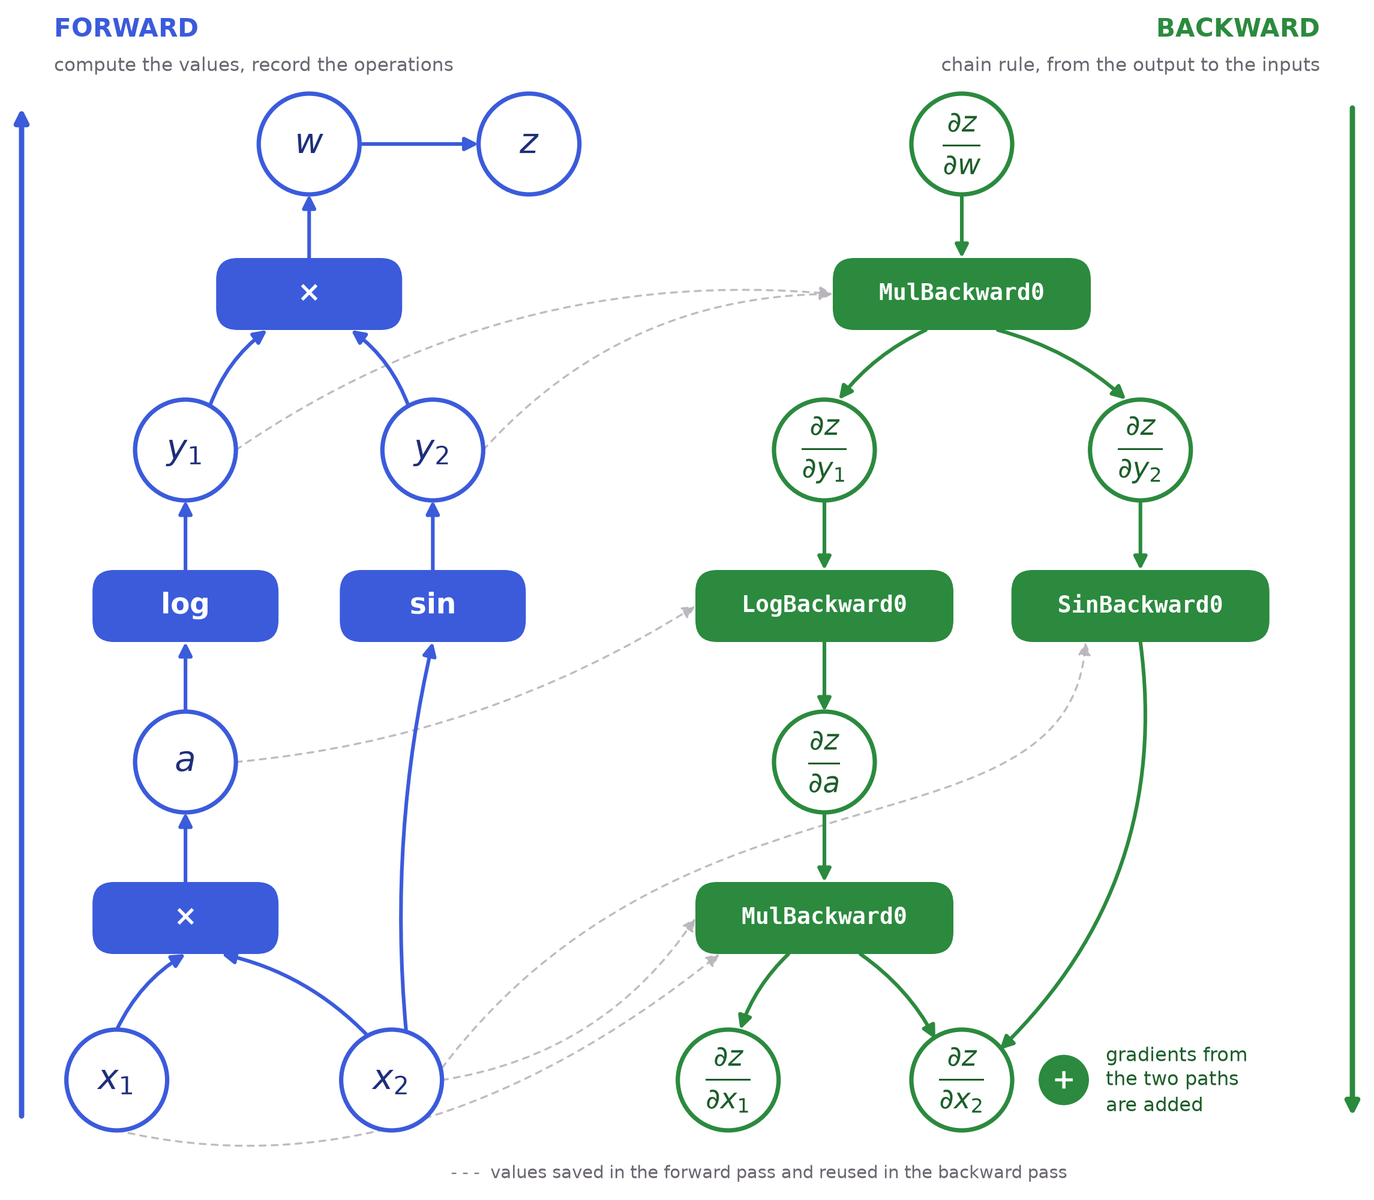

## What actually is PyTorch?

It can be your best friend or your worst nightmare, depending on which background you have, and what platform you're using (but we luckly have Colab <3)

PyTorch (from now on torch) is a powerful tool for DeepLearning, however it can be used for any kind of (gradient) optimization, as we will see

## How to use it

### Intro

Installation can be tricky, particularly if you need to install the support for cuda. Linux Ubuntu/Debian is usually a good environment.

In [1]:
import torch
import numpy as np
from tqdm.auto import tqdm  # progress bars for the training loops

Torch has many functionalities, that you can find in [the documentation](https://pytorch.org/docs/stable/index.html), functionalities that encodes some sort of computations (data manipulation, activation functions, tensor manipulation and so on)

![](https://pbs.twimg.com/media/E10ffa9X0AA4H2_.png)

### Tensors


However, everything requires some sort of tensors (n-dimensional arrays), and there are a handful of versions that you might want to keep in mind.

In [2]:
a = torch.tensor([10, 100]) # Vector!

b = torch.tensor(10) # Scalar!

print('a:', a, ', size:', a.size())
print('b:', b, ', size:', b.size())

a: tensor([ 10, 100]) , size: torch.Size([2])
b: tensor(10) , size: torch.Size([])


In [3]:
c = torch.tensor([[1,2], [3,4]]) # Matrix
print('c:', c, ', size:', c.size())

d = torch.tensor([[[1,2], [3,4]], [[10,20], [30,40]]]) # (actual) Tensor!
print('d:', d, ', size:', d.size())

c: tensor([[1, 2],
        [3, 4]]) , size: torch.Size([2, 2])
d: tensor([[[ 1,  2],
         [ 3,  4]],

        [[10, 20],
         [30, 40]]]) , size: torch.Size([2, 2, 2])


We can of course manipulate individual cells of the tensors

In [4]:
c[0, 0] = 10000 # first top row element!
print('c:', c, ', size:', c.size())


c: tensor([[10000,     2],
        [    3,     4]]) , size: torch.Size([2, 2])


But we can also manipulate tensors selecting some of their dimensions:

In [5]:
print('The first column of c:', c[:, 0])

The first column of c: tensor([10000,     3])


In [6]:
print('The first MATRIX in d:\n', d[0, :, :])
print('The second MATRIX in d:\n', d[1, :, :])

The first MATRIX in d:
 tensor([[1, 2],
        [3, 4]])
The second MATRIX in d:
 tensor([[10, 20],
        [30, 40]])


In [7]:
d[0, :, :] = torch.tensor([[2,1],[4,3]], device=d.device, dtype=d.dtype)
print('d:', d)

d: tensor([[[ 2,  1],
         [ 4,  3]],

        [[10, 20],
         [30, 40]]])


However, both of them have a very specific requirements, which is that whatever is inside, has to share the same type.
This is to efficiently allocate memory!

Torch will do some automatic casting, but we can set the DataType at creation!

In [8]:
print(torch.tensor([10, 10.1]))
print(torch.tensor([10, 10.1], dtype=torch.float))
print(torch.tensor([10, 10.1], dtype=torch.int))

print(torch.tensor(10) * torch.tensor(10.0))
print(torch.tensor(10, dtype=torch.float) * torch.tensor(10.0, dtype=torch.int))

tensor([10.0000, 10.1000])
tensor([10.0000, 10.1000])
tensor([10, 10], dtype=torch.int32)
tensor(100.)
tensor(100.)


In [9]:
print(torch.tensor([True, False]))
print(torch.tensor([True, False], dtype=torch.int))


tensor([ True, False])
tensor([1, 0], dtype=torch.int32)


We can also perform operations with tensors of different datatype, very useful!


In [10]:
print(torch.tensor([True, False])*torch.tensor([10, 10]))

tensor([10,  0])


In [11]:
a1 = torch.tensor([1])
print('a1 dtype:', a1.dtype)
a2 = torch.tensor([1.0])
print('a2 dtype:', a2.dtype)

a1 dtype: torch.int64
a2 dtype: torch.float32


Similar to numpy, we can also create tensors of zeros and ones:

In [12]:
print(torch.zeros((1, 2))) # We need to input the desired sizes size
print(torch.ones((1, 2)))

tensor([[0., 0.]])
tensor([[1., 1.]])


It's also very helpful to create tensors of zeros and ones by copying the dimension of other tensors.

In [13]:
print(torch.ones_like(d))
print(torch.zeros_like(c))

tensor([[[1, 1],
         [1, 1]],

        [[1, 1],
         [1, 1]]])
tensor([[0, 0],
        [0, 0]])


We can also set where to store our tensors, the central memory (RAM) and the memory of one of our GPUs!

In [ ]:
torch.is_

In [14]:
cpu_tensor = torch.tensor([1], device=torch.device('cpu'))
gpu_tensor = torch.tensor([1], device=torch.device('cuda'))

print('cpu_tensor:', cpu_tensor, 'device =', cpu_tensor.device)
print('gpu_tensor:', gpu_tensor)

AssertionError: Torch not compiled with CUDA enabled

cpu_tensor is on device 'cpu' so it's on the RAM!
gpu_tensor is on device 'cuda:0' so it's on the memory of the first GPU!

Torch supports cuda computations, so we need gpus with cuda cores (the green ones!)

**PSA:** Torch is very numpy friendly (they can go back and forth from np arrays to torch tensors), however, there is a very inconvenient scenario in both directions:  
 1. Torch to np: you loose the gradient
 2. np to torch: the tensor keeps the NumPy dtype, which is `float64` by default, while torch layers work in `float32`: convert with `.float()` (e.g. `torch.from_numpy(a).float()`), or create the array as `float32` as we do later for the linear regression

In [15]:
cpu_tensor.numpy()

array([1])

In [16]:
gpu_tensor.numpy()

TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

Oh no, we can't convert tensors stored on the gpus to numpy?

We can, but we first need to move the tensor to the RAM!

In [17]:
gpu_tensor.cpu().numpy()

array([1])

In some cases you need to do also [this](https://pytorch.org/docs/stable/generated/torch.Tensor.detach.html):

In [18]:
gpu_tensor.detach().cpu().numpy()

array([1])

# Anyways, most DeepLearning stuff is POOP.

![](https://i.redd.it/gpp8gmh0on861.jpg)

### Functions

Torch provides a ton of functionalities, and it's useless list here all possible ones, however feel free to use any online resource if you need to find a function that does a certain computation:

Heres the most useful ones:  
 1. `torch.nn` contains everything you can think that might be useful for neural networks
 2. `torch.optim` gradient optimizers
 3. `torch.random` for sampling
 4. math functions are directly in `torch` (`torch.exp`, `torch.log`, `torch.sin`, ...), with `torch.linalg` for linear algebra and `torch.special` for special functions

### Gradient

Gradients are a big part of torch, as it provides an _automatic differentiation_ framework (God save for the chain-rule)

Torch actually has two very different ways of computing a derivative, so let's look at both on the same function, $f(x) = \sin(x)$, whose derivative we know: $f'(x) = \cos(x)$.

 1. `torch.gradient` works on **data**: it gets the values $f(x_i)$ on a grid of points and estimates the slope from the neighbouring points (finite differences, $\frac{f(x_{i+1}) - f(x_{i-1})}{x_{i+1} - x_{i-1}}$). It never sees the function itself.
 2. **autograd** works on the **computation**: a tensor with `requires_grad=True` remembers the operations applied to it (here `sin`), and `.backward()` applies the exact derivative of each operation, chaining them together.

In [19]:
f = torch.sin                                   # the function: we know its derivative is cos
x = torch.linspace(0, 2 * torch.pi, 9)          # 9 points, spacing h = pi/4 (coarse on purpose)

# 1) torch.gradient: only sees the sampled values f(x_i) and estimates the slope from the neighbours
(grad_numeric,) = torch.gradient(f(x), spacing=(x,))

# 2) autograd: records the operation (sin) and applies its exact derivative
x_ag = x.clone().requires_grad_(True)
f(x_ag).sum().backward()                        # backward() needs a scalar: the sum gives x_ag.grad[i] = sin'(x_i)
grad_autograd = x_ag.grad

exact = torch.cos(x)
print('     x   torch.gradient   autograd   exact cos(x)')
for xi, gn, ga, ex in zip(x, grad_numeric, grad_autograd, exact):
    print(f'{xi:6.3f}   {gn:12.4f}   {ga:8.4f}   {ex:10.4f}')

# more points: torch.gradient gets closer, autograd is exact anyway
for n in [9, 100, 1000]:
    x = torch.linspace(0, 2 * torch.pi, n)
    (g_num,) = torch.gradient(torch.sin(x), spacing=(x,))
    x_ag = x.clone().requires_grad_(True)
    torch.sin(x_ag).sum().backward()
    print(f'{n:5d} points | largest error  torch.gradient: {(g_num - torch.cos(x)).abs().max():.1e}'
          f'   autograd: {(x_ag.grad - torch.cos(x)).abs().max():.1e}')

     x   torch.gradient   autograd   exact cos(x)
 0.000         0.9003     1.0000       1.0000
 0.785         0.6366     0.7071       0.7071
 1.571         0.0000    -0.0000      -0.0000
 2.356        -0.6366    -0.7071      -0.7071
 3.142        -0.9003    -1.0000      -1.0000
 3.927        -0.6366    -0.7071      -0.7071
 4.712         0.0000     0.0000       0.0000
 5.498         0.6366     0.7071       0.7071
 6.283         0.9003     1.0000       1.0000
    9 points | largest error  torch.gradient: 1.0e-01   autograd: 0.0e+00
  100 points | largest error  torch.gradient: 6.7e-04   autograd: 0.0e+00
 1000 points | largest error  torch.gradient: 1.3e-05   autograd: 0.0e+00


Look at the table: autograd gives exactly $\cos(x)$ at every point, while `torch.gradient` is close but always about 10% too small. With a spacing $h = \pi/4$ the finite difference of $\sin$ gives $\cos(x) \cdot \frac{\sin h}{h} \approx 0.90 \cos(x)$. With more points `torch.gradient` gets better (10 times more points, about 100 times less error), while autograd is exact whatever the grid.

That's why ML is built on autograd: we need the exact gradient of the loss with respect to all the parameters of the model, and the function (our code) is always there. `torch.gradient` is the tool for when all we have are values on a grid, like a measured signal.

In [20]:
#@title Interactive plot: the parabola behind each torch.gradient value { display-mode: "form" }

#@markdown How does `torch.gradient` get those numbers? For each point it takes the point and its two neighbours, fits the only parabola that passes through these three points, and returns the slope of that parabola at the middle point. Every point gets its own parabola, used once and thrown away. At the two ends there is only one neighbour, so it uses the straight line through the two points.

#@markdown Move the slider: the purple curve is the parabola, the green line is its slope at the middle point (the value `torch.gradient` returns) and the dashed line is the true slope $\cos(x)$. At the top and the bottom of the sine (points 2 and 6) the parabola is symmetric and its slope is exactly 0, as it should be; everywhere else the parabola is not the sine, and the two slopes differ.

# HTML + JavaScript: the slider runs directly in the browser, so it moves instantly
from IPython.display import HTML, display
import uuid

widget = r"""
<div id="pb-UID" style="font-family: -apple-system, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif; max-width: 760px; background: #ffffff; color: #222; padding: 14px 16px; border: 1px solid #e3e3e3; border-radius: 10px;">
  <div style="display: flex; align-items: center; gap: 12px; margin: 0 0 6px;">
    <label style="font-size: 14px; color: #555;">point i</label>
    <input type="range" min="0" max="8" value="1" step="1" class="pb-slider" style="flex: 1; accent-color: #7F77DD;">
    <span class="pb-i" style="font-size: 15px; font-weight: 600; min-width: 14px;">1</span>
  </div>
  <svg class="pb-plot" viewBox="0 0 700 330" width="100%" role="img" aria-label="sin(x) sampled on 9 points, with the parabola torch.gradient fits at the selected point"></svg>
  <div style="display: flex; gap: 16px; flex-wrap: wrap; font-size: 13px; color: #555; margin: 2px 0 12px;">
    <span><span style="color: #b5b3ad;">&#9473;</span> f(x) = sin(x)</span>
    <span><span style="color: #7F77DD;">&#9473;</span> parabola through the 3 points (a line at the ends)</span>
    <span><span style="color: #1D9E75;">&#9473;</span> its slope at x<sub>i</sub> = torch.gradient</span>
    <span><span style="color: #D85A30;">&#9476;</span> true slope cos(x<sub>i</sub>)</span>
  </div>
  <div style="display: grid; grid-template-columns: repeat(3, 1fr); gap: 10px;">
    <div style="background: #f4f4f6; border-radius: 8px; padding: 10px 12px;"><div style="font-size: 12px; color: #666;">torch.gradient</div><div class="pb-b" style="font-size: 22px; font-weight: 600; color: #1D9E75;"></div></div>
    <div style="background: #f4f4f6; border-radius: 8px; padding: 10px 12px;"><div style="font-size: 12px; color: #666;">true slope cos(x<sub>i</sub>)</div><div class="pb-t" style="font-size: 22px; font-weight: 600; color: #D85A30;"></div></div>
    <div style="background: #f4f4f6; border-radius: 8px; padding: 10px 12px;"><div style="font-size: 12px; color: #666;">difference</div><div class="pb-e" style="font-size: 22px; font-weight: 600;"></div></div>
  </div>
</div>
<script>
(function () {
  const root = document.getElementById('pb-UID');
  const N = 9, X = [], F = [];
  for (let k = 0; k < N; k++) { X.push(2 * Math.PI * k / (N - 1)); F.push(Math.sin(X[k])); }   // same points as above
  const L = 44, R = 680, T = 18, B = 290, x0 = -0.4, x1 = 2 * Math.PI + 0.4, y0 = -1.6, y1 = 1.6;
  const px = x => L + (x - x0) / (x1 - x0) * (R - L), py = y => B - (y - y0) / (y1 - y0) * (B - T);
  const svg = root.querySelector('.pb-plot');
  const fmt = v => (Math.abs(v) < 5e-5 ? 0 : v).toFixed(4);
  function seg(xa, ya, xb, yb, c, w, dash) {
    return `<line x1="${px(xa)}" y1="${py(ya)}" x2="${px(xb)}" y2="${py(yb)}" stroke="${c}" stroke-width="${w}" ${dash ? 'stroke-dasharray="7 5"' : ''} stroke-linecap="round"/>`;
  }
  function draw(i) {
    let s = '';
    s += `<line x1="${L}" y1="${py(0)}" x2="${R}" y2="${py(0)}" stroke="#e6e6e6" stroke-width="1"/>`;
    let pts = '';
    for (let k = 0; k <= 160; k++) { const x = x0 + (x1 - x0) * k / 160; pts += `${px(x)},${py(Math.sin(x))} `; }
    s += `<polyline points="${pts}" fill="none" stroke="#c9c7c1" stroke-width="3"/>`;
    const xi = X[i], fi = F[i], t = Math.cos(xi);
    let b;
    if (i > 0 && i < N - 1) {
      // parabola through (x[i-1], f[i-1]), (x[i], f[i]), (x[i+1], f[i+1]) written around x[i]: f[i] + b d + c d^2
      const hl = xi - X[i - 1], hr = X[i + 1] - xi, sl = (fi - F[i - 1]) / hl, sr = (F[i + 1] - fi) / hr;
      b = (hl * sr + hr * sl) / (hl + hr);
      const c = (sr - sl) / (hl + hr);
      let pp = '';
      for (let k = 0; k <= 60; k++) { const x = X[i - 1] - 0.45 + (hl + hr + 0.9) * k / 60, d = x - xi; pp += `${px(x)},${py(fi + b * d + c * d * d)} `; }
      s += `<polyline points="${pp}" fill="none" stroke="#7F77DD" stroke-width="2.5"/>`;
    } else {
      // at the ends only one neighbour: straight line through 2 points
      const j = i === 0 ? 1 : N - 2;
      b = (F[j] - F[i]) / (X[j] - X[i]);
      const xa = Math.min(X[i], X[j]) - 0.45, xb = Math.max(X[i], X[j]) + 0.45;
      s += seg(xa, fi + b * (xa - xi), xb, fi + b * (xb - xi), '#7F77DD', 2.5, false);
    }
    s += seg(xi - 1.0, fi - 1.0 * t, xi + 1.0, fi + 1.0 * t, '#D85A30', 2, true);
    s += seg(xi - 1.0, fi - 1.0 * b, xi + 1.0, fi + 1.0 * b, '#1D9E75', 3, false);
    for (let k = 0; k < N; k++) {
      const used = (i > 0 && i < N - 1) ? (k >= i - 1 && k <= i + 1) : (i === 0 ? k <= 1 : k >= N - 2);
      s += `<circle cx="${px(X[k])}" cy="${py(F[k])}" r="${k === i ? 7 : 5}" fill="${used ? '#7F77DD' : '#ffffff'}" stroke="${used ? '#534AB7' : '#888'}" stroke-width="1.5"/>`;
      s += `<text x="${px(X[k])}" y="${B + 22}" text-anchor="middle" font-size="12" fill="#777">${k}</text>`;
    }
    svg.innerHTML = s;
    root.querySelector('.pb-i').textContent = i;
    root.querySelector('.pb-b').textContent = fmt(b);
    root.querySelector('.pb-t').textContent = fmt(t);
    root.querySelector('.pb-e').textContent = fmt(b - t);
  }
  const slider = root.querySelector('.pb-slider');
  slider.addEventListener('input', () => draw(+slider.value));
  draw(+slider.value);
})();
</script>
"""

display(HTML(widget.replace("UID", uuid.uuid4().hex[:8])))

## Let's start doing interesting stuff

If you got everything to this point, you are pretty much able to code anything in the DeepLearning community, well done

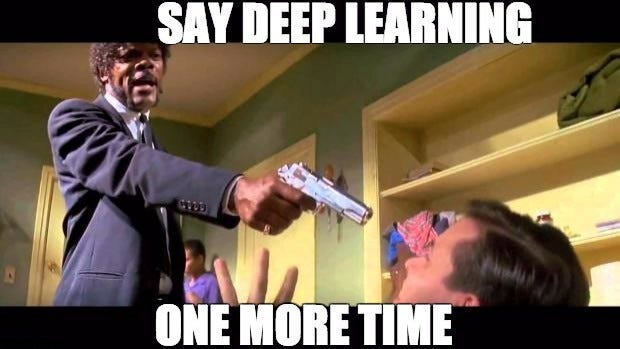


As for all respected optimization tutorials, why not starting from our favourite model implementing it together...

linear regression :-)

### Simplified 101 linear regression - aka estimate the average

Since I wanted to give you a simple example of what the whole code should look like, let's look into linear regression to estimate a linear function, by minimizing the mean squared error over a training dataset:
$$
L(\theta) = \frac{1}{N}\sum_{i=0}^N (y_i - f_\theta(x_i))^2
$$

$$
f_\theta(x) = Ax +b
$$

In [21]:
# create dummy data for training
x_values = [i for i in range(11)]
x_train = np.array(x_values, dtype=np.float32)
x_train = x_train.reshape(-1, 1)

y_values = [2*i + 1 for i in x_values]
y_train = np.array(y_values, dtype=np.float32)
y_train = y_train.reshape(-1, 1)

print(x_train)
print(y_train)

[[ 0.]
 [ 1.]
 [ 2.]
 [ 3.]
 [ 4.]
 [ 5.]
 [ 6.]
 [ 7.]
 [ 8.]
 [ 9.]
 [10.]]
[[ 1.]
 [ 3.]
 [ 5.]
 [ 7.]
 [ 9.]
 [11.]
 [13.]
 [15.]
 [17.]
 [19.]
 [21.]]


We use poop, our regressor is a class that inherits from the ```torch.nn.Module``` class.

Every Model we create has to inherit from it. (even if it's not a NN)

In [22]:
class linearRegression(torch.nn.Module):
    def __init__(self, inputSize, outputSize, device=None):
        super(linearRegression, self).__init__()

        # I like to set the device manually for each model I define
        if device is None:
            device = torch.device('cpu')
        self.device = device

        # This linear (layer) has an input dim and an output dim
        self.linear = torch.nn.Linear(inputSize, outputSize, device=self.device)


    # This model applies a linear transformation to the input!
    # y = Ax + b
    def forward(self, x):
        out = self.linear(x)
        return out

    def cuda(self, n=0):
        self.device = torch.device('cuda:0')
        self.linear.to(self.device)

For each model we build, we define the constructor (`__init__`) and the `forward` function.

Then we are ready to use and train the model!

In [23]:
inputDim = 1        # takes variable 'x'
outputDim = 1       # takes variable 'y'

model = linearRegression(inputDim, outputDim)

model(torch.tensor([1.]))

tensor([-0.2286], grad_fn=<ViewBackward0>)

Notice the output of our model! We have its actual output and its `grad_fn`, the operation that produced it: autograd will use it to compute the gradients when we call `.backward()`.

Notice that this model is R -> R: `torch.nn.Linear(1, 1)` reads the **last** dimension of its input as the features, so it expects one number per example. To evaluate it on many inputs at once, they go in a batch of shape `(N, 1)`: N examples, 1 feature each.

What if we pass ten numbers as a flat vector of shape `(10,)`? For the model this is *one* example with *ten* features, and the matrix product inside `Linear` cannot work: look at the error in the next cell, `mat1 and mat2 shapes cannot be multiplied (1x10 and 1x1)`. Making the batch dimension explicit fixes it: `torch.tensor([1.]*10).reshape(-1, 1)` has shape `(10, 1)` and gives ten outputs. This is also why `x_train` and `y_train` were reshaped with `.reshape(-1, 1)` above.

In [24]:
model(torch.tensor([1.]*10))                    # shape (10,): one example with 10 features -> error
# model(torch.tensor([1.]*10).reshape(-1, 1))   # shape (10, 1): 10 examples with 1 feature -> 10 outputs

RuntimeError: mat1 and mat2 shapes cannot be multiplied (1x10 and 1x1)

In [25]:
learningRate = 0.01
epochs = 100

##### For GPU #######
if torch.cuda.is_available():
    model.cuda()

print('model.device =', model.device)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learningRate)

model.device = cuda:0


In [26]:
for epoch in tqdm(range(epochs), desc='training'):
    # Converting inputs and labels to Variable
    if torch.cuda.is_available():
        inputs = torch.from_numpy(x_train).cuda()
        labels = torch.from_numpy(y_train).cuda()
    else:
        inputs = torch.from_numpy(x_train)
        labels = torch.from_numpy(y_train)

    # Clear gradient buffers because we don't want any gradient from previous epoch to carry forward, dont want to cummulate gradients
    optimizer.zero_grad()

    # get output from the model, given the inputs
    outputs = model(inputs)

    # get loss for the predicted output
    loss = criterion(outputs, labels)
    print(loss)
    # get gradients w.r.t to parameters
    loss.backward()

    # update parameters
    optimizer.step()

    print('epoch {}, loss {}'.format(epoch, loss.item()))

training:   0%|          | 0/100 [00:00<?, ?it/s]

tensor(260.7004, device='cuda:0', grad_fn=<MseLossBackward0>)
epoch 0, loss 260.70037841796875
tensor(21.2747, device='cuda:0', grad_fn=<MseLossBackward0>)
epoch 1, loss 21.274682998657227
tensor(1.7454, device='cuda:0', grad_fn=<MseLossBackward0>)
epoch 2, loss 1.7453699111938477
tensor(0.1523, device='cuda:0', grad_fn=<MseLossBackward0>)
epoch 3, loss 0.15231409668922424
tensor(0.0223, device='cuda:0', grad_fn=<MseLossBackward0>)
epoch 4, loss 0.022261982783675194
tensor(0.0115, device='cuda:0', grad_fn=<MseLossBackward0>)
epoch 5, loss 0.01154426857829094
tensor(0.0106, device='cuda:0', grad_fn=<MseLossBackward0>)
epoch 6, loss 0.010561443865299225
tensor(0.0104, device='cuda:0', grad_fn=<MseLossBackward0>)
epoch 7, loss 0.01037384569644928
tensor(0.0103, device='cuda:0', grad_fn=<MseLossBackward0>)
epoch 8, loss 0.010252317413687706
tensor(0.0101, device='cuda:0', grad_fn=<MseLossBackward0>)
epoch 9, loss 0.010137366130948067
tensor(0.0100, device='cuda:0', grad_fn=<MseLossBackward

As you can see, the loss goes down!

Les's see the prediction performance, when we use the model for prediction we don't (usually) want to compute the network's gradients, so we use this code:

In [27]:
with torch.no_grad():
    y_hat = model(torch.from_numpy(x_train).to(model.device))

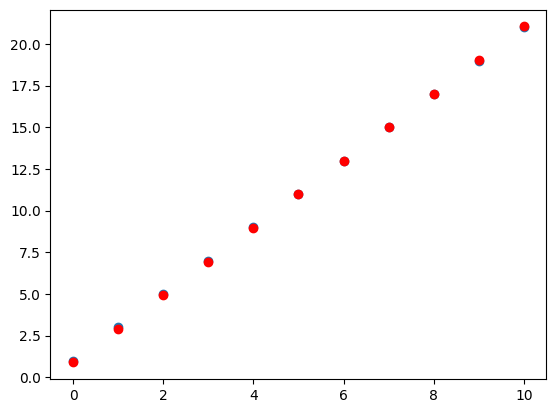

In [28]:
import matplotlib.pyplot as plt
plt.figure()
plt.scatter(x_train, y_train)
plt.scatter(x_train, y_hat.detach().cpu().numpy(), c='r')

plt.show()

Are optimizers just black magic? NO, they are just wrappers to very non-readable mathematical gibberish that applies the gradient to your varaibles, keeping track of extra informations (for adaptive settings or momentum)


### Your turn, time for linear regression

Well, first, maybe it's better to create a dataset... since we don't like naive stuff, let's say that we can create a synthetic dataset where:
$$
x \sim U(0.5, 5.0),\,\,\, \text{(say 100 samples)}\\
y = log(x) + \epsilon, \,\,\, \epsilon \sim N(0, 0.05)\\
L(\theta) = \sum_{x,y}\left[(wx+b) - y\right]^2
$$

In [29]:
x = 4.5 * torch.rand((100,1)) + 0.5
y = torch.log(x) + torch.randn((100,1))*0.1

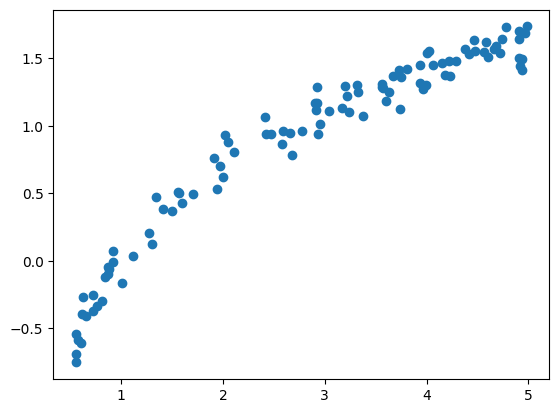

In [30]:
import matplotlib.pyplot as plt
plt.scatter(x[:, 0], y[:, 0])

Looks good to me, now let's try to fit a linear model on it with torch:
$$
y = wx+b
$$

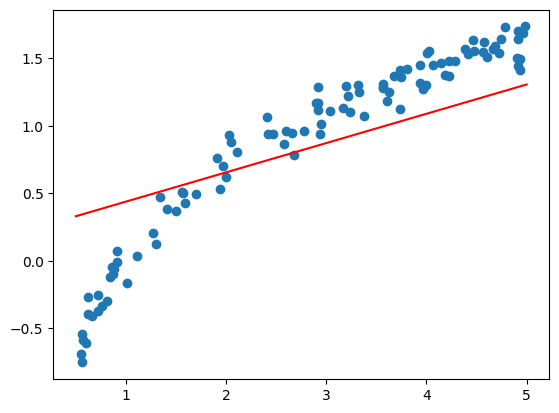

In [31]:
N = x.size()[0]

linear_model = linearRegression(1, 1)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.SGD(linear_model.parameters(), lr=learningRate)

plt.scatter(x, y)
with torch.no_grad():
    y_hat = [linear_model(torch.tensor([0.5])).detach().numpy()[0],
             linear_model(torch.tensor([5.0])).detach().numpy()[0]]
# detach the output value from the model's computational graph
plt.plot([0.5, 5.0], y_hat, c="red")

# If we repeat this code multiple times we will see different red lines.

Same as before!

In [32]:
for epoch in tqdm(range(epochs), desc='training'):
    inputs = x
    labels = y

    # Clear gradient buffers because we don't want any gradient from previous epoch to carry forward, dont want to cummulate gradients
    optimizer.zero_grad()

    # get output from the model, given the inputs
    outputs = linear_model(inputs)

    # get loss for the predicted output
    loss = criterion(outputs, labels)
    print(loss)
    # get gradients w.r.t to parameters
    loss.backward()

    # update parameters
    optimizer.step()

    print('epoch {}, loss {}'.format(epoch, loss.item()))

training:   0%|          | 0/100 [00:00<?, ?it/s]

tensor(0.1662, grad_fn=<MseLossBackward0>)
epoch 0, loss 0.1661585569381714
tensor(0.1526, grad_fn=<MseLossBackward0>)
epoch 1, loss 0.15259984135627747
tensor(0.1441, grad_fn=<MseLossBackward0>)
epoch 2, loss 0.14413347840309143
tensor(0.1387, grad_fn=<MseLossBackward0>)
epoch 3, loss 0.1387496441602707
tensor(0.1352, grad_fn=<MseLossBackward0>)
epoch 4, loss 0.13523255288600922
tensor(0.1328, grad_fn=<MseLossBackward0>)
epoch 5, loss 0.1328466385602951
tensor(0.1311, grad_fn=<MseLossBackward0>)
epoch 6, loss 0.13114698231220245
tensor(0.1299, grad_fn=<MseLossBackward0>)
epoch 7, loss 0.1298643946647644
tensor(0.1288, grad_fn=<MseLossBackward0>)
epoch 8, loss 0.1288360059261322
tensor(0.1280, grad_fn=<MseLossBackward0>)
epoch 9, loss 0.12796328961849213
tensor(0.1272, grad_fn=<MseLossBackward0>)
epoch 10, loss 0.1271866112947464
tensor(0.1265, grad_fn=<MseLossBackward0>)
epoch 11, loss 0.12646989524364471
tensor(0.1258, grad_fn=<MseLossBackward0>)
epoch 12, loss 0.12579131126403809
te

linear_model.linear.weight: [[0.32856247]]
linear_model.linear.bias: [0.02690216]


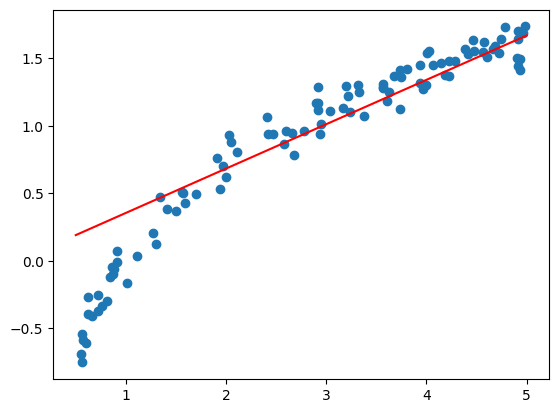

In [33]:
print('linear_model.linear.weight:', linear_model.linear.weight.detach().cpu().numpy())
print('linear_model.linear.bias:', linear_model.linear.bias.detach().cpu().numpy())

plt.scatter(x, y)
with torch.no_grad():
    y_hat = [linear_model(torch.tensor([0.5])).detach().numpy()[0],
             linear_model(torch.tensor([5.0])).detach().numpy()[0]]
         # detach the output value from the model's computational graph
plt.plot([0.5, 5.0], y_hat, c="red")


However, we are engineers, and we would do some more analysis on the model and see that the residuals are kinda bad, and so you would try to alter the data to improve it, right?

Text(0, 0.5, 'residual')

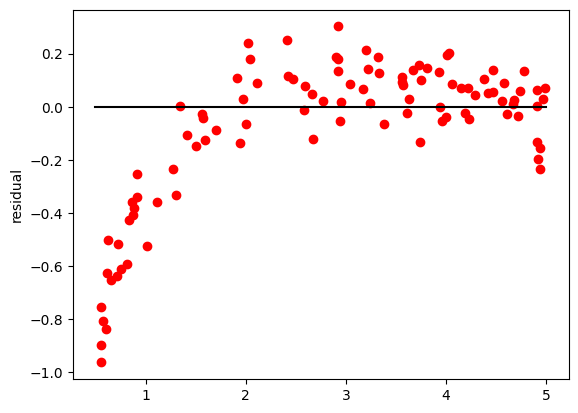

In [34]:
with torch.no_grad():
    y_train_hat = linear_model(x)
plt.scatter(x, (y-y_train_hat).detach().cpu().numpy(), c='r')
plt.plot([0.5, 5.0], [0,0], c="black")
plt.ylabel("residual")

Well, the error is logarithmic, strange right?

Let's add a log term to our model.

In [35]:
class logRegression(torch.nn.Module):
    def __init__(self, inputSize, outputSize, device=None):
        super(logRegression, self).__init__()

        # I like to set the device manually for each model I define
        if device is None:
            device = torch.device('cpu')
        self.device = device

        # This linear (layer) has an input dim and an output dim
        self.linear = torch.nn.Linear(inputSize, outputSize, device=self.device)


    # This model applies a linear transformation to the log of input!
    # y = A*log(x) + b
    def forward(self, x):
        out = self.linear(torch.log(x))
        return out

    def cuda(self, n=0):
        self.device = torch.device('cuda:0')
        self.linear.to(self.device)

Please if you define an optimization loop, do it in a method, I'm already tired of seeing repeated code.

In [36]:
log_model = logRegression(1,1)

learningRate = 0.05

criterion = torch.nn.MSELoss()
optimizer = torch.optim.SGD(log_model.parameters(), lr=learningRate)

for epoch in tqdm(range(epochs), desc='training'):
    inputs = x
    labels = y

    # Clear gradient buffers because we don't want any gradient from previous epoch to carry forward, dont want to cummulate gradients
    optimizer.zero_grad()

    # get output from the model, given the inputs
    outputs = log_model(inputs)

    # get loss for the predicted output
    loss = criterion(outputs, labels)
    print(loss)
    # get gradients w.r.t to parameters
    loss.backward()

    # update parameters
    optimizer.step()

    print('epoch {}, loss {}'.format(epoch, loss.item()))

training:   0%|          | 0/100 [00:00<?, ?it/s]

tensor(0.3237, grad_fn=<MseLossBackward0>)
epoch 0, loss 0.3236781358718872
tensor(0.2707, grad_fn=<MseLossBackward0>)
epoch 1, loss 0.2706943154335022
tensor(0.2339, grad_fn=<MseLossBackward0>)
epoch 2, loss 0.23388166725635529
tensor(0.2076, grad_fn=<MseLossBackward0>)
epoch 3, loss 0.20759795606136322
tensor(0.1882, grad_fn=<MseLossBackward0>)
epoch 4, loss 0.18820767104625702
tensor(0.1734, grad_fn=<MseLossBackward0>)
epoch 5, loss 0.17336662113666534
tensor(0.1616, grad_fn=<MseLossBackward0>)
epoch 6, loss 0.16156147420406342
tensor(0.1518, grad_fn=<MseLossBackward0>)
epoch 7, loss 0.1518135964870453
tensor(0.1435, grad_fn=<MseLossBackward0>)
epoch 8, loss 0.14348869025707245
tensor(0.1362, grad_fn=<MseLossBackward0>)
epoch 9, loss 0.1361740529537201
tensor(0.1296, grad_fn=<MseLossBackward0>)
epoch 10, loss 0.12959982454776764
tensor(0.1236, grad_fn=<MseLossBackward0>)
epoch 11, loss 0.12358822673559189
tensor(0.1180, grad_fn=<MseLossBackward0>)
epoch 12, loss 0.1180209368467331
t

log_model.linear.weight: [[0.95407987]]
log_model.linear.bias: [0.07055308]


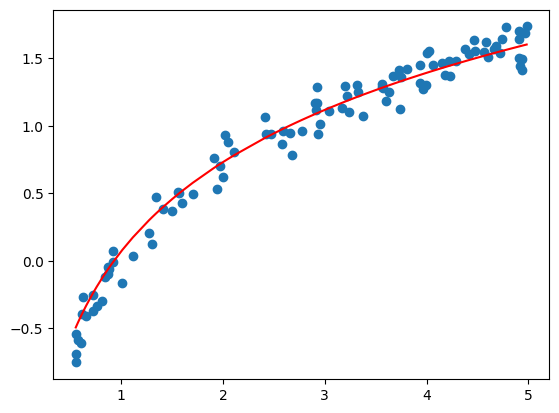

In [37]:
print('log_model.linear.weight:', log_model.linear.weight.detach().cpu().numpy())
print('log_model.linear.bias:', log_model.linear.bias.detach().cpu().numpy())

plt.scatter(x, y)
x_sort,_ = torch.sort(x, 0) # just fort the plot

with torch.no_grad():
    y_hat = log_model(x_sort).detach().numpy()[:, 0] # detach the output value from the model's computational graph
plt.plot(x_sort, y_hat, c="red")


Say we want to use mean absolute error as loss and not mean squared error, we just need to change it in the code, and torch will handle the rest

In [38]:
log_model = logRegression(1,1)

criterion = torch.nn.L1Loss()
optimizer = torch.optim.SGD(log_model.parameters(), lr=learningRate)

for epoch in tqdm(range(epochs), desc='training'):
    inputs = x
    labels = y

    # Clear gradient buffers because we don't want any gradient from previous epoch to carry forward, dont want to cummulate gradients
    optimizer.zero_grad()

    # get output from the model, given the inputs
    outputs = log_model(inputs)

    # get loss for the predicted output
    loss = criterion(outputs, labels)
    print(loss)
    # get gradients w.r.t to parameters
    loss.backward()

    # update parameters
    optimizer.step()

    print('epoch {}, loss {}'.format(epoch, loss.item()))

training:   0%|          | 0/100 [00:00<?, ?it/s]

tensor(0.8680, grad_fn=<MeanBackward0>)
epoch 0, loss 0.8680427074432373
tensor(0.7937, grad_fn=<MeanBackward0>)
epoch 1, loss 0.7937012314796448
tensor(0.7207, grad_fn=<MeanBackward0>)
epoch 2, loss 0.7206928730010986
tensor(0.6492, grad_fn=<MeanBackward0>)
epoch 3, loss 0.6492468118667603
tensor(0.5814, grad_fn=<MeanBackward0>)
epoch 4, loss 0.5813664793968201
tensor(0.5155, grad_fn=<MeanBackward0>)
epoch 5, loss 0.5155335068702698
tensor(0.4499, grad_fn=<MeanBackward0>)
epoch 6, loss 0.44992750883102417
tensor(0.3859, grad_fn=<MeanBackward0>)
epoch 7, loss 0.3859085440635681
tensor(0.3240, grad_fn=<MeanBackward0>)
epoch 8, loss 0.32397663593292236
tensor(0.2687, grad_fn=<MeanBackward0>)
epoch 9, loss 0.26868224143981934
tensor(0.2204, grad_fn=<MeanBackward0>)
epoch 10, loss 0.22040821611881256
tensor(0.1805, grad_fn=<MeanBackward0>)
epoch 11, loss 0.180509552359581
tensor(0.1550, grad_fn=<MeanBackward0>)
epoch 12, loss 0.15500926971435547
tensor(0.1434, grad_fn=<MeanBackward0>)
epoc

log_model.linear.weight: [[1.0184766]]
log_model.linear.bias: [0.01768566]


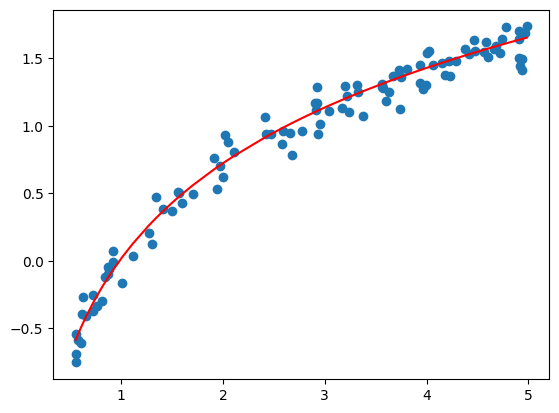

In [39]:
print('log_model.linear.weight:', log_model.linear.weight.detach().cpu().numpy())
print('log_model.linear.bias:', log_model.linear.bias.detach().cpu().numpy())

plt.scatter(x, y)
x_sort,_ = torch.sort(x, 0) # just fort the plot

with torch.no_grad():
    y_hat = log_model(x_sort).detach().numpy()[:, 0] # detach the output value from the model's computational graph

plt.plot(x_sort, y_hat, c="red")

Very Nice!

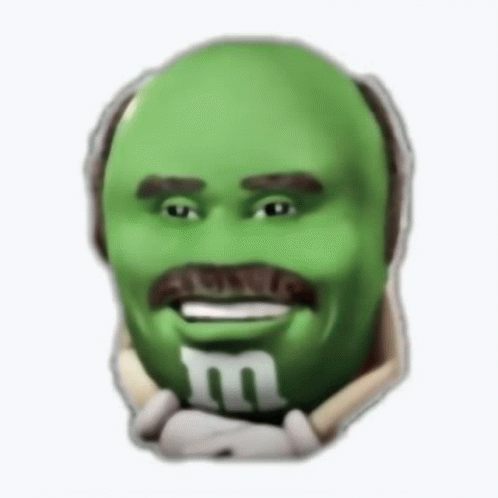

### Even PCA?

Well, we won't really implement PCA, that has some constraint on the definition of the matrixes, but at the end of the day, is purely a linear transformation of the data, and it has been proven that any linear transformation of it will lead to the same solution or to an equivalent one (same loss)

So, what we need is to minimize the following:
$$
L(\theta) = \sum_x (W^T(Wx) - x)^2
$$
Thus, we first project $x$ to a lower dimensional space via $W$, and via $W^$ we project it back to the original one, and we hope that such projection-back reconstruct $x$ as good as possible (for simplicity, we assume that the mean is 0, so we don't need the bias, but it's trivially fixable, feel free to try)

In [40]:
class PCA_model(torch.nn.Module):
    def __init__(self, inputSize, outputSize, device=None):
        super(PCA_model, self).__init__()

        # I like to set the device manually for each model I define
        if device is None:
            device = torch.device('cpu')
        self.device = device

        # We are manually defining a parameter of the model
        # We need to use this class and tell the model that it should train it
        self.W = torch.nn.Parameter(torch.randn((outputSize, inputSize))*.75,
                                    requires_grad=True) # <--- this allows gradient descend/ascend

    # This model applies a linear transformation to each vector in the input batch
    # y = A*x
    def forward(self, x):
        out = torch.bmm(self.W.repeat(x.size(dim=0), 1, 1), x.unsqueeze(-1))
        return out

    def perform_pca(self, x):
        y = self(x)

        #print('y.size():', y.size())

        return torch.bmm(self.W.t().repeat(x.size(dim=0), 1, 1), y).squeeze(-1)

    def cuda(self, n=0):
        self.device = torch.device('cuda:0')
        self.linear.to(self.device)

In [41]:
data = torch.randn((100,10)) * 5.0

pca_model = PCA_model(data.size()[1], outputSize=2)

optimizer = torch.optim.Adam(pca_model.parameters(), lr=5e-2)
criterion = torch.nn.MSELoss()  # squared reconstruction error, as in PCA

epochs = 1000

for epoch in tqdm(range(epochs), desc='training'):
    inputs = data
    labels = data

    # Clear gradient buffers because we don't want any gradient from previous epoch to carry forward, dont want to cummulate gradients
    optimizer.zero_grad()

    # get output from the model, given the inputs
    outputs = pca_model.perform_pca(inputs)

    #print('inputs.size():', inputs.size())
    #print('outputs.size():', outputs.size())

    # get loss for the predicted output
    loss = criterion(outputs, labels)
    print(loss)
    # get gradients w.r.t to parameters
    loss.backward()

    # update parameters
    optimizer.step()

    print('epoch {}, loss {}'.format(epoch, loss.item()))

training:   0%|          | 0/1000 [00:00<?, ?it/s]

tensor(174.5202, grad_fn=<MseLossBackward0>)
epoch 0, loss 174.52020263671875
tensor(140.3178, grad_fn=<MseLossBackward0>)
epoch 1, loss 140.31777954101562
tensor(113.3801, grad_fn=<MseLossBackward0>)
epoch 2, loss 113.38011169433594
tensor(92.3864, grad_fn=<MseLossBackward0>)
epoch 3, loss 92.38642120361328
tensor(76.0838, grad_fn=<MseLossBackward0>)
epoch 4, loss 76.08380126953125
tensor(63.4190, grad_fn=<MseLossBackward0>)
epoch 5, loss 63.41900634765625
tensor(53.5700, grad_fn=<MseLossBackward0>)
epoch 6, loss 53.56997299194336
tensor(45.9088, grad_fn=<MseLossBackward0>)
epoch 7, loss 45.908809661865234
tensor(39.9528, grad_fn=<MseLossBackward0>)
epoch 8, loss 39.952823638916016
tensor(35.3269, grad_fn=<MseLossBackward0>)
epoch 9, loss 35.32692337036133
tensor(31.7380, grad_fn=<MseLossBackward0>)
epoch 10, loss 31.73804473876953
tensor(28.9571, grad_fn=<MseLossBackward0>)
epoch 11, loss 28.957149505615234
tensor(26.8055, grad_fn=<MseLossBackward0>)
epoch 12, loss 26.805522918701172

MSE closed form: 16.599786397975485 - MSE gradient solution: 16.768327713012695


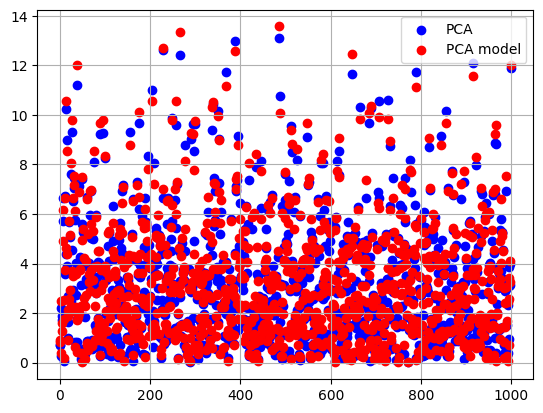

In [42]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
res = pca.fit_transform(data)
rec = pca.inverse_transform(res)

with torch.no_grad():
    rec_model=pca_model.perform_pca(data)

error_model = ((rec_model - data).detach().cpu().numpy()**2)
error_pca = ((data.numpy() - rec)**2)

print(f"MSE closed form: {error_pca.mean()} - MSE gradient solution: {error_model.mean()}")

plt.figure()
plt.scatter(np.arange(error_pca.size), np.sqrt(error_pca), color='b', label='PCA')
plt.scatter(np.arange(error_pca.size), np.sqrt(error_model), color='r', label='PCA model')
plt.grid()
plt.legend()
plt.show()

## Neural network time


Ever coded a neural network from scratch? Well, for those who said not, it's time to finally do it right?

For the data, say we will have 6 dimensions, some will be used, some won't

In [43]:
data = torch.randn((1000, 6))
# the target is unreadable on purpose, I'm just applying random non linear transformation to the data, plus some noise
targets = torch.sqrt(torch.abs((data[:, 0] * 10)**2 + torch.exp(data[:, 1]) - (data[:, 3] + data[:, 5])/torch.abs(data[:, 4]))) + torch.randn((1000,))
targets = targets.unsqueeze(-1)

Now, let's recall that a fully connected layer is composed by the following:
$$
x \in R^n\\
W \in R^{n\times m}\\
b \in R^m\\
\\
output = \sigma(Wx + b)\\
$$

Well, doesn't seem too different from what we have done so far right? Then let's go on implementing it (the index in the variable refers to each layer)

In [44]:
import copy

class NN_model(torch.nn.Module):
    def __init__(self, inputSize, outputSize, hidden_size=1000, n_hidden=2, activation='relu', device=None):
        super(NN_model, self).__init__()

        # I like to set the device manually for each model I define
        if device is None:
            device = torch.device('cpu')
        self.device = device

        # Variable size and depth
        layers = [torch.nn.Linear(inputSize, hidden_size)]
        for _ in range(n_hidden):
            layers.append(torch.nn.Linear(hidden_size, hidden_size))
        layers.append(torch.nn.Linear(hidden_size, outputDim))

        # The parameter list is important, if we don't use it, the optimization doesn't work
        self.layers = torch.nn.ParameterList(layers)

        # implemented activation for hiddden layers
        if activation == 'relu':
            self.activation = torch.nn.ReLU()
        else:
            raise NotImplementedError(activation)


    # This model applies a linear transformation to each layer and then a nonlinear activation function
    def forward(self, x):
        out = copy.deepcopy(x)
        for l in self.layers[:-1]:
            out = self.activation(l(out))

        return self.layers[-1](out) # Last layer is just a linear transformation

    def cuda(self, n=0):
        self.device = torch.device('cuda:'+str(n))
        for l in self.layers[:-1]:
            l.to(self.device)

    def fit(self, inputs, labels, optimizer, criterion, epochs=100):
        for epoch in tqdm(range(epochs), desc='training'):
            # Clear gradient buffers because we don't want any gradient from previous epoch to carry forward, dont want to cummulate gradients
            optimizer.zero_grad()

            # get output from the model, given the inputs
            outputs = self(inputs)

            # get loss for the predicted output
            loss = criterion(outputs, labels)
            print(loss)
            # get gradients w.r.t to parameters
            loss.backward()

            # update parameters
            optimizer.step()

            print('epoch {}, loss {}'.format(epoch, loss.item()))


In [45]:
hyperparams = {'inputSize': 6,
               'outputSize': 1,
               'hidden_size': 500,
               'n_hidden': 3,
               'activation': 'relu'}

nn_regressor = NN_model(**hyperparams)

criterion = torch.nn.MSELoss()
optimizer = torch.optim.Adam(nn_regressor.parameters(), lr=1e-3)

nn_regressor.fit(data, targets, optimizer, criterion, epochs=1000)

training:   0%|          | 0/1000 [00:00<?, ?it/s]

tensor(102.1202, grad_fn=<MseLossBackward0>)
epoch 0, loss 102.12020111083984
tensor(96.9508, grad_fn=<MseLossBackward0>)
epoch 1, loss 96.95075988769531
tensor(88.0952, grad_fn=<MseLossBackward0>)
epoch 2, loss 88.09523010253906
tensor(72.1707, grad_fn=<MseLossBackward0>)
epoch 3, loss 72.170654296875
tensor(49.0286, grad_fn=<MseLossBackward0>)
epoch 4, loss 49.02864074707031
tensor(29.6382, grad_fn=<MseLossBackward0>)
epoch 5, loss 29.638221740722656
tensor(50.9585, grad_fn=<MseLossBackward0>)
epoch 6, loss 50.9584846496582
tensor(45.0233, grad_fn=<MseLossBackward0>)
epoch 7, loss 45.02329635620117
tensor(31.0195, grad_fn=<MseLossBackward0>)
epoch 8, loss 31.01946258544922
tensor(27.8875, grad_fn=<MseLossBackward0>)
epoch 9, loss 27.887460708618164
tensor(31.2360, grad_fn=<MseLossBackward0>)
epoch 10, loss 31.235998153686523
tensor(34.5955, grad_fn=<MseLossBackward0>)
epoch 11, loss 34.595516204833984
tensor(35.5223, grad_fn=<MseLossBackward0>)
epoch 12, loss 35.52225875854492
tensor

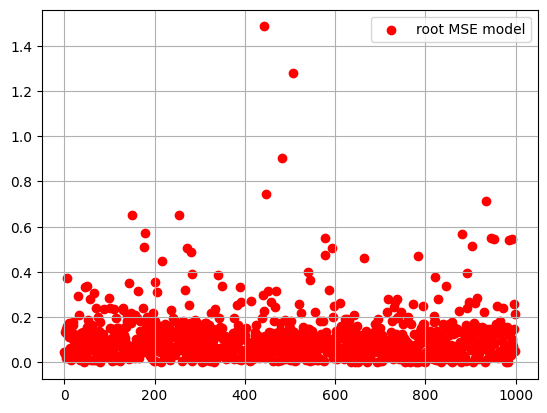

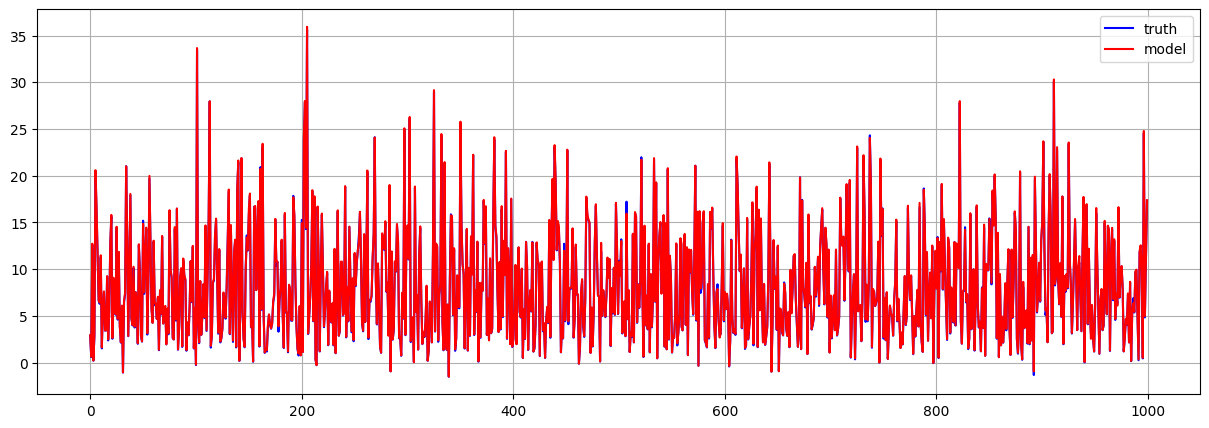

In [46]:
with torch.no_grad():
    y_hat = nn_regressor(data)

error_model = ((y_hat - targets).detach().cpu().numpy()**2)

plt.figure()
plt.scatter(np.arange(error_model.size), np.sqrt(error_model), color='r', label='root MSE model')
plt.grid()
plt.legend()
plt.show()

with torch.no_grad():
    y_hat = nn_regressor(data)

plt.figure(figsize=(15, 5))
plt.plot(targets, color='b', label='truth')
plt.plot(y_hat, color='r', label='model')
plt.grid()
plt.legend()
plt.show()

And now, thanks to the magic of OOP, you can mix your blocks of code with parts coming from other developers, hopefully without loosing too many hours adapting it

### Real world scenario

In [47]:
from __future__ import print_function
import argparse
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.optim.lr_scheduler import StepLR
from tqdm.auto import tqdm


class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, 3, 1)
        self.conv2 = nn.Conv2d(32, 64, 3, 1)
        self.dropout1 = nn.Dropout(0.25)
        self.dropout2 = nn.Dropout(0.5)
        self.fc1 = nn.Linear(9216, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(x)
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, 2)
        x = self.dropout1(x)
        x = torch.flatten(x, 1)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.dropout2(x)
        x = self.fc2(x)
        output = F.log_softmax(x, dim=1)
        return output


def train(model, device, train_loader, optimizer, epoch, log_interval=1000):
    model.train()
    with tqdm(total=len(train_loader), desc=f'epoch {epoch}', leave=False) as bar:
        for batch_idx, (data, target) in enumerate(train_loader):
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            output = model(data)
            loss = F.nll_loss(output, target)
            loss.backward()
            optimizer.step()
            bar.update(1)
            if batch_idx % log_interval == 0:
                print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                    epoch, batch_idx * len(data), len(train_loader.dataset),
                    100. * batch_idx / len(train_loader), loss.item()))


def test(model, device, test_loader):
    model.eval()
    test_loss = 0
    correct = 0
    with torch.no_grad():
        for data, target in test_loader:
            data, target = data.to(device), target.to(device)
            output = model(data)
            test_loss += F.nll_loss(output, target, reduction='sum').item()  # sum up batch loss
            pred = output.argmax(dim=1, keepdim=True)  # get the index of the max log-probability
            correct += pred.eq(target.view_as(pred)).sum().item()

    test_loss /= len(test_loader.dataset)

    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        100. * correct / len(test_loader.dataset)))


In [48]:
# Training settings
### PyTorch MNIST Example'
batch_size = 64
test_batch_size=1000
epochs = 14
lr = 0.1
gamma=0.7
seed=1

use_cuda = torch.cuda.is_available()

# VERY important:
torch.manual_seed(seed)

What is a [seed](https://en.wikipedia.org/wiki/Random_seed)? Basicaslly it's a very important number for sampling.

Try to run the cells below multiple times:

In [49]:
torch.manual_seed(1)
random = torch.randn((1000, 6))

print(random)

tensor([[-1.5256, -0.7502, -0.6540, -1.6095, -0.1002, -0.6092],
        [-0.9798, -1.6091, -0.7121,  0.3037, -0.7773, -0.2515],
        [-0.2223,  1.6871,  0.2284,  0.4676, -0.6970, -1.1608],
        ...,
        [-1.3221,  0.4623,  0.5322,  0.1049, -0.4030, -2.8451],
        [ 1.0732,  0.1381, -0.3351,  0.9270, -1.1018, -0.5892],
        [-0.0561, -1.2283,  1.1443, -0.3844,  0.1175,  0.6503]])


In [50]:
torch.manual_seed(2)
random = torch.randn((1000, 6))

print(random)

tensor([[-1.0408,  0.9166, -1.3042, -1.1097, -1.2188,  1.1676],
        [-1.0574, -0.1188, -0.9078,  0.3452, -0.5713, -0.2351],
        [ 1.0076, -0.7529, -0.2250, -0.4327, -1.5071, -0.4586],
        ...,
        [-0.0733,  1.5552,  0.8871, -0.9172,  0.4484,  0.1917],
        [ 0.4739,  1.0308,  1.4528, -0.0377, -0.2737, -0.8912],
        [ 0.1813, -0.4132, -0.4716,  0.3874, -0.2087,  0.1307]])


If we manually set a the seed for sampling, we can reproduce the sampling results!

Thats the reason that statistics in ML are extracted by performing multiple executions changing the seed.

In [ ]:
if use_cuda:
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

train_kwargs = {'batch_size': batch_size}
test_kwargs = {'batch_size': test_batch_size}

if use_cuda:
    cuda_kwargs = {'num_workers': 1,
                    'pin_memory': True,
                    'shuffle': True}
    train_kwargs.update(cuda_kwargs)
    test_kwargs.update(cuda_kwargs)

transform=transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])

dataset1 = datasets.MNIST('data', train=True, download=True,
                    transform=transform)
dataset2 = datasets.MNIST('data', train=False,
                    transform=transform)
train_loader = torch.utils.data.DataLoader(dataset1,**train_kwargs)
test_loader = torch.utils.data.DataLoader(dataset2, **test_kwargs)

model = Net().to(device)
optimizer = optim.Adadelta(model.parameters(), lr=lr)

scheduler = StepLR(optimizer, step_size=1, gamma=gamma)
for epoch in tqdm(range(1, epochs + 1), desc='epochs'):
    train(model, device, train_loader, optimizer, epoch)
    test(model, device, test_loader)
    scheduler.step()

epochs:   0%|          | 0/14 [00:00<?, ?it/s]

epoch 1:   0%|          | 0/938 [00:00<?, ?it/s]

Train Epoch: 1 [0/60000 (0%)]	Loss: 2.319956

Test set: Average loss: 0.0760, Accuracy: 9760/10000 (98%)



epoch 2:   0%|          | 0/938 [00:00<?, ?it/s]

Train Epoch: 2 [0/60000 (0%)]	Loss: 0.114801

Test set: Average loss: 0.0556, Accuracy: 9817/10000 (98%)



epoch 3:   0%|          | 0/938 [00:00<?, ?it/s]

Train Epoch: 3 [0/60000 (0%)]	Loss: 0.020960

Test set: Average loss: 0.0465, Accuracy: 9850/10000 (98%)



epoch 4:   0%|          | 0/938 [00:00<?, ?it/s]

Train Epoch: 4 [0/60000 (0%)]	Loss: 0.152773


That was all from me, hope that it was clear and that you liked it, feel free to experiment a bit, next time we will start from here and use the custom training loop that we saw earlier to train a RL agent

Have funnnnnnnnn


![](https://media.tenor.com/lfDHEnYIUk4AAAAC/this-is-where-the-fun-begins-star-wars.gif)

## (Fun) Exercises

For the braves, I leave here some exercises (they should be pretty simple) to explore a bit and test your knowledge.

I'll give you the main structure of the code and you can just complete it, however, to achieve the same results, there are hundreds of ways, so if you find my scaffolding too cumbersome, or you think there is a better way (let alone possible errors), feel free to experiment... ad if you have questions, feel free to write me at [alberto.sinigaglia@phd.unipd.it](mailto:alberto.sinigaglia@phd.unipd.it)

### Batch Normalization

[Batch Normalization](https://arxiv.org/abs/1502.03167) is a very famous building block for neural networks, it is fundamental for big models, as it solves (tackles at least) a very famous problem in deep hierarchical models, called _internal covariate shift_... in poor words, when you change the parameters in the initial layers, their change is amplified by the change in the next layers, and when you get to the final layers, you have a completely different representation for the same image, thus the final layer has to be trained from scratch.

What BN do is pretty simple, and it's, as the name suggests, a normalization of each batch (intra network, so it's not just a preprocessing).
Given a batch of data of size $N$, BN applied to the $M$th layer, forward propagates the batch in the previous layers, obtaining the batch tensor $t$, and does the following:
$$
\mu = \frac{\sum_{i=0}^N t_i}{N} \\
\sigma^2 = \frac{\sum_{i=0}^N (t_i - \mu)^2}{N} \\
\hat{t} = \frac{t - \mu}{\sqrt{\sigma^2 + \epsilon}}\\
t_\text{final} = \gamma \hat{t} + \beta
$$
in poor words, it first normalizes the batch, and then rescales and shift the tensor using $\beta, \gamma$, which are trained parameters, so that the network is free to learn where is best to have such distribution.

Let's create a Layer that does exactly that (actually, usually $\mu, \sigma$ are moving average, because you need a good statistic for this to work)

Use the BatchNorm [Layer](https://pythonguides.com/pytorch-batch-normalization/)

### Residual connection

[Residual networks](https://arxiv.org/abs/1512.03385) are the other big famous super used building block for big networks. They solve an orthogonal problem to the one of BN, which is the vanishing gradient. What was observed before ResNet was that deep networks performed better than shallow networks, up to a certain point, and then performances worsened.

The problem is that given a N layer network, you can easily approximate it with a M layer network (M > N), by setting its first N layers with the same weights as the other network, and then the last M-N with an identity function.

However, layers are initialized so that they approximate the zero-function (weights close to 0), so the network has a hard time learning the identity.

To solve that, they just added a residual connection, which is "you some to your output, your input" (given that they have the same shape, otherwise you can concatenate it in some way):
$$
y_i = F(x_i) + x_i
$$
That's all... the intuition is that $F(x_i)$ is initialized with the 0-function, so if it's useless (like the last M-N layers in the previous example), you can just not learn anything in the last layers, and forward the information.

You can also think this as a "gradient descent" idea, where indeed GD has as update $x_i = x_i + F(x_i)$, where $F$ is just the gradient.


Let's code it!

### Dropout

[Dropout](https://arxiv.org/abs/1207.0580) is a very famous regularization method proposed from Hinton, that has a toooon of intuitions behind it... in very few words, it just randomly sets values to 0 with some probability (that you choose)

You can see this as a "regularization" since the network cannot rely always on the same information/neuron to predict, or you can see this as a cheap way of training an ensemble of neural networks.

To do so, we just do the following:
$$
m \sim Be(1-p) ^ {N} \\
y_i = F(x_i) \cdot m
$$

So it's pretty simple, we just need to create a layer that samples random binary masks form a Bernoulli distribution, and multiply. Here $p$ is the probability of *dropping* a neuron (as in `torch.nn.Dropout`), so each neuron is kept with probability $1-p$.
At test time, we keep all the neurons on and we rescale the activation by $1-p$ (during training only a fraction $1-p$ of the neurons was active, so if you activate all connections without rescaling you "overstimulate" the next neuron). PyTorch implements the equivalent *inverted* dropout: it divides the kept activations by $1-p$ during training and does nothing at test time.

Let's do it.

![](https://media.tenor.com/JOJ1qSZon7UAAAAC/shia-labeouf-just-do-it.gif)